In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

BASE_DIR = Path(
    r"D:\Veda Internship\Sakshi\Super_Store_DataCleaning"
    r"\COVID19_Global_Impact_Dashboard"
    r"\Day5_Covid19_Global_Impact_Dashboard"
)

OUTPUT_DIR  = BASE_DIR / "cleaned_data"
DATA_PATH = BASE_DIR / "Dataset" / "owid-covid-data.csv"

CHART_DIR = BASE_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = BASE_DIR / "cleaned_data" / "covid19_day3_analysis.csv"

print("Project folder:", BASE_DIR)
print("Original file exists:", DATA_PATH.exists())

Project folder: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard\Day5_Covid19_Global_Impact_Dashboard
Original file exists: True


In [7]:
df = pd.read_csv(DATA_PATH, low_memory=False)

df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Unique locations:", df["location"].nunique())

display(df.head())
display(df.isnull().sum().sort_values(ascending=False).head(15))

Dataset shape: (429435, 67)
Date range: 2020-01-01 00:00:00 to 2024-08-14 00:00:00
Unique locations: 255


,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN


weekly_icu_admissions                      418442
weekly_icu_admissions_per_million          418442
excess_mortality                           416024
excess_mortality_cumulative_absolute       416024
excess_mortality_cumulative                416024
excess_mortality_cumulative_per_million    416024
weekly_hosp_admissions                     404938
weekly_hosp_admissions_per_million         404938
icu_patients_per_million                   390319
icu_patients                               390319
hosp_patients_per_million                  388779
hosp_patients                              388779
total_boosters_per_hundred                 375835
total_boosters                             375835
new_vaccinations                           358464
dtype: int64

In [8]:
columns = [
    "iso_code", "continent", "location", "date", "population",
    "total_cases", "new_cases", "new_cases_smoothed",
    "total_deaths", "new_deaths", "new_deaths_smoothed",
    "total_cases_per_million", "total_deaths_per_million",
    "people_vaccinated", "people_fully_vaccinated",
    "people_vaccinated_per_hundred",
    "people_fully_vaccinated_per_hundred",
    "total_vaccinations_per_hundred"
]

available_columns = [c for c in columns if c in df.columns]
clean_df = df[available_columns].copy()

# Exclude aggregate regions such as World and continents
if "iso_code" in clean_df.columns:
    clean_df = clean_df[
        ~clean_df["iso_code"].astype(str).str.startswith("OWID_")
    ].copy()

clean_df = clean_df.dropna(subset=["location", "date"])
clean_df = clean_df.drop_duplicates(subset=["location", "date"])

numeric_columns = clean_df.select_dtypes(include="number").columns

# Missing values remain missing; don't automatically replace them with zero
# Remove impossible negative population values
if "population" in clean_df.columns:
    clean_df.loc[clean_df["population"] <= 0, "population"] = np.nan

# Derived metric
if {"total_cases", "total_deaths"}.issubset(clean_df.columns):
    clean_df["case_fatality_rate_pct"] = (
        clean_df["total_deaths"]
        .div(clean_df["total_cases"].replace(0, np.nan))
        * 100
    )

# 7-day rolling average, calculated separately for each location
if "new_cases" in clean_df.columns:
    clean_df = clean_df.sort_values(["location", "date"])
    clean_df["new_cases_7day_avg"] = (
        clean_df.groupby("location")["new_cases"]
        .transform(lambda s: s.rolling(7, min_periods=7).mean())
    )

clean_df.to_csv(OUTPUT_DIR / "covid19_day5_cleaned.csv", index=False)

print("Cleaned shape:", clean_df.shape)
print("Duplicate location/date rows:",
      clean_df.duplicated(["location", "date"]).sum())
print("Saved:", OUTPUT_DIR / "covid19_day5_cleaned.csv")

Cleaned shape: (393903, 20)
Duplicate location/date rows: 0
Saved: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard\Day5_Covid19_Global_Impact_Dashboard\cleaned_data\covid19_day5_cleaned.csv


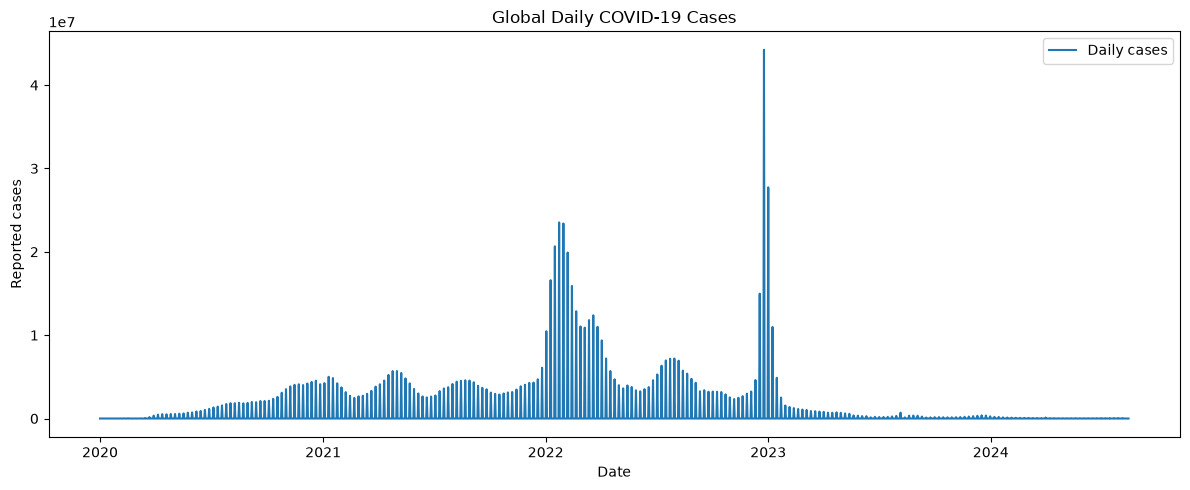

In [10]:
#Chart 1: Global COVID-19 cases trend 
global_df = clean_df.groupby("date", as_index=False).agg(
    cases=("new_cases", "sum"),
    deaths=("new_deaths", "sum")
)

plt.figure(figsize=(12, 5))
plt.plot(global_df["date"], global_df["cases"], label="Daily cases")
plt.title("Global Daily COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("Reported cases")
plt.legend()
plt.tight_layout()
plt.savefig(CHART_DIR / "01_global_cases_trend.png", dpi=150)
plt.show()

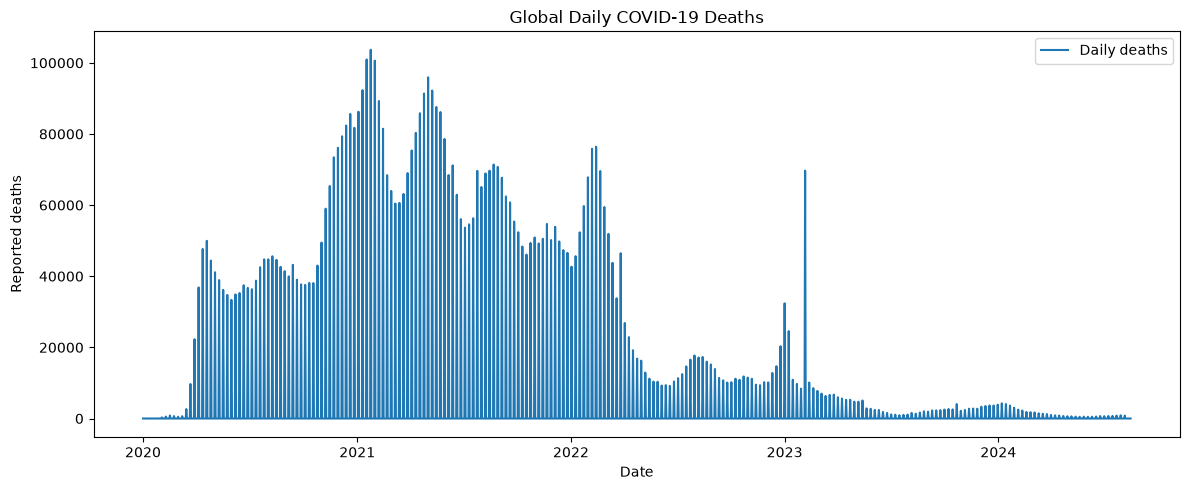

In [11]:
#Chart 2: Global deaths trend
plt.figure(figsize=(12, 5))
plt.plot(global_df["date"], global_df["deaths"], label="Daily deaths")
plt.title("Global Daily COVID-19 Deaths")
plt.xlabel("Date")
plt.ylabel("Reported deaths")
plt.legend()
plt.tight_layout()
plt.savefig(CHART_DIR / "02_global_deaths_trend.png", dpi=150)
plt.show()

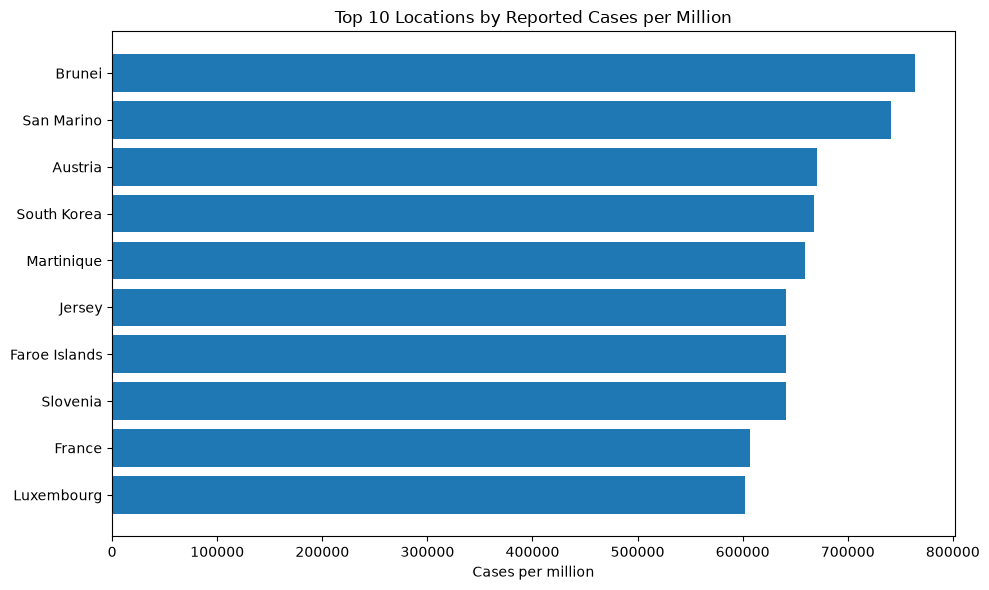

In [12]:
#Chart 3: Top 10 countries by reported cases per million
latest = (
    clean_df.sort_values("date")
    .groupby("location", as_index=False)
    .tail(1)
)

top_cases = (
    latest.dropna(subset=["total_cases_per_million"])
    .nlargest(10, "total_cases_per_million")
    .sort_values("total_cases_per_million")
)

plt.figure(figsize=(10, 6))
plt.barh(top_cases["location"], top_cases["total_cases_per_million"])
plt.title("Top 10 Locations by Reported Cases per Million")
plt.xlabel("Cases per million")
plt.tight_layout()
plt.savefig(CHART_DIR / "03_top_cases_per_million.png", dpi=150)
plt.show()

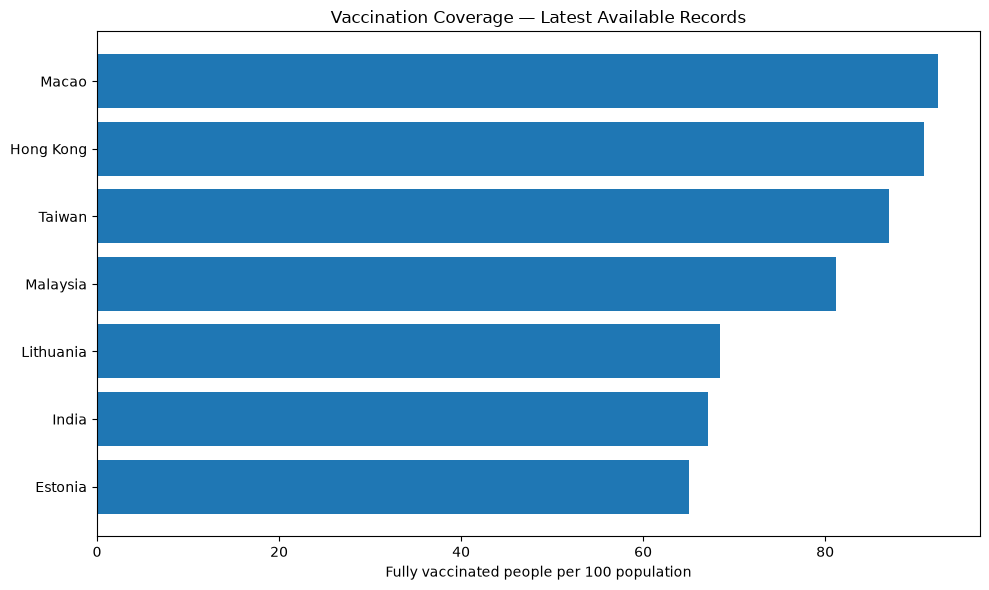

In [13]:
#Chart 4: Vaccination coverage
if "people_fully_vaccinated_per_hundred" in clean_df.columns:
    vaccination = (
        latest.dropna(subset=["people_fully_vaccinated_per_hundred"])
        .nlargest(10, "people_fully_vaccinated_per_hundred")
        .sort_values("people_fully_vaccinated_per_hundred")
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        vaccination["location"],
        vaccination["people_fully_vaccinated_per_hundred"]
    )
    plt.title("Vaccination Coverage — Latest Available Records")
    plt.xlabel("Fully vaccinated people per 100 population")
    plt.tight_layout()
    plt.savefig(CHART_DIR / "04_vaccination_coverage.png", dpi=150)
    plt.show()

In [ ]:
#3–5 key insights
1.Cases trend: “Reported daily cases peaked around 2023, indicating a major reporting wave in the selected dataset.”
2.Deaths trend: “Reported daily deaths peaked around 2021. The timing differed from the case peak.”
3.Country comparison: “Brnuei showed a high reported cumulative case rate per million among the selected locations.”
4.Vaccination: “Macao recorded  around 90 to 95 % fully vaccinated people per 100 in its latest available record.”
5.Limitations: “Reported cases and deaths depend on testing, reporting practices, and data availability, so cross-country comparisons require caution.”